In [1]:
import starfile

In [2]:
data = starfile.read('/goliath/processing/Gouaux/CJS/BestTomo/ProcessingJElocal/tomograms/20231026_HippAu_14/fiducial_tracking/aunps/aunp_tm.star')

In [16]:
coors = data[data['faTM_PeakScore']>0.4][['faTM_PeakZ','faTM_PeakY','faTM_PeakX']].to_numpy()

In [70]:
# Use RANSAC to fit a plane to the data
from sklearn.linear_model import RANSACRegressor
from sklearn.linear_model import LinearRegression
import numpy as np

ransac = RANSACRegressor(LinearRegression(), residual_threshold=1, max_trials=1000)
ransac.fit(coors[:,1:3], coors[:,0])

print(ransac.estimator_.coef_, ransac.estimator_.intercept_)

# Get all points within 10 of plane
near_mask = np.abs(coors[:,0] - ransac.predict(coors[:,1:3])) < 10
center = np.array([375,500,500]) // 2
away_mask = np.sign(coors[:,0] - ransac.predict(coors[:,1:3])) != np.sign(center[0]- ransac.predict(np.expand_dims(center[1:3],0)))
sel_mask = np.logical_or(near_mask,away_mask)

new_coors = coors[~sel_mask]
ransac2 = RANSACRegressor(LinearRegression(), residual_threshold=1, max_trials=1000)
ransac2.fit(new_coors[:,1:3], new_coors[:,0])

print(ransac2.estimator_.coef_, ransac2.estimator_.intercept_)

# Get all points within 5 of plane
near_mask = np.abs(coors[:,0] - ransac2.predict(coors[:,1:3])) < 10
center = np.array([375,500,500]) // 2
away_mask = np.sign(coors[:,0] - ransac2.predict(coors[:,1:3])) != np.sign(center[0]- ransac2.predict(np.expand_dims(center[1:3],0)))
sel_mask2 = np.logical_or(near_mask,away_mask)



[0.12806044 0.00670262] 210.2946857472213
[0.13827346 0.01299592] -7.3745216712920225


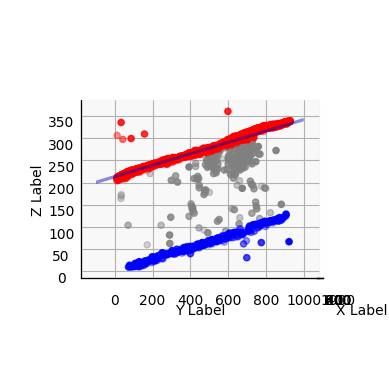

In [71]:

from matplotlib import pyplot as plt
fig = plt.figure()

# Add a 3D axis
ax = fig.add_subplot(111, projection='3d', proj_type = 'ortho')
#Change roation
ax.view_init(elev=0, azim=0)
# Create a 3D scatter plot
inliers = coors[sel_mask]
inliers2 = coors[sel_mask2]
outliers = coors[~np.logical_or(sel_mask,sel_mask2)]
ax.scatter(outliers[:,2], outliers[:,1], outliers[:,0], c='grey')

ax.scatter(inliers[:,2], inliers[:,1], inliers[:,0],c='r')
ax.scatter(inliers2[:,2], inliers2[:,1], inliers2[:,0],c='b')

# Set labels
ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

xx, yy = np.meshgrid(np.linspace(-100, 1000, 80), np.linspace(-100, 1000, 80))
zz = ransac.predict(np.c_[yy.ravel(), xx.ravel()]).reshape(xx.shape)

# Plot the fitted plane
ax.plot_surface(xx, yy, zz, color='blue', alpha=0.5)


# Show the plot
plt.show()

In [67]:
np.expand_dims(np.array([250,250]),0)


array([[250, 250]])